# Inland Excess Water (IEW) Monitoring — SegFormer-B0

Self-contained notebook implementing **SegFormer-B0** (Xie et al., 2021) as a backbone for the IEW segmentation pipeline, following the same training recipe as `01_unet_backbone.ipynb` through `03_rupnet_backbone.ipynb` (Table 1 backbone comparison).

**Paper reference:** Xie et al., *SegFormer: Simple and Efficient Design for Semantic Segmentation with Transformers*, NeurIPS 2021.

Flow: imports → data pipeline → visualization → loss functions → model → dataloaders → training → loss curves → evaluation → prediction visualization.

## Deviations from the IEW paper (§4.1)

Two intentional changes from the baseline notebook recipe:

1. **Patch size 128 instead of 64.** SegFormer's encoder downsamples by ×4 (stage 1), ×2×2×2 = ×32 total. With 64×64 patches the deepest stage would operate on 2×2 tokens — too few for meaningful attention. 128×128 gives 4×4 at the deepest stage (16 tokens) and 32×32 at the shallowest (1024 tokens with SR=8 → 16 K/V tokens). The stride is also 128 (non-overlapping), so total patch counts are ~4× lower than the 64-stride setup (~13k vs ~52k), but each patch covers 4× the spatial area.

2. **SegFormer-B0 implemented from scratch** (no external `mmseg`/`timm` dependency) so the notebook is fully self-contained. Architecture matches the published B0 spec exactly: embed_dims=[32,64,160,256], depths=[2,2,2,2], num_heads=[1,2,5,8], sr_ratios=[8,4,2,1], All-MLP decoder with decoder_dim=256.

Everything else (Adam / lr=1e-4 / 100 epochs / batch=32 / GDL+WFL / class encoding) matches §4.1 verbatim.

## 1. Imports and Setup

In [ ]:
import sys
print(f"Kernel Python: {sys.executable}")

# Force-reinstall torch to clear the corrupted installation (the ~orch remnant).
# Run this cell once, then **Restart Kernel**, then re-run from the top.
!"{sys.executable}" -m pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu -q
print("Reinstall complete — RESTART KERNEL, then run all cells from the top.")

In [45]:
import os
import sys
import glob
import math
import time
import yaml
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import Window
from pathlib import Path
from typing import List, Dict, Tuple

torch.manual_seed(0)
np.random.seed(0)

print(f"PyTorch {torch.__version__} | CUDA available: {torch.cuda.is_available()}")


PyTorch 2.6.0+cpu | CUDA available: False


## 2. Data Pipeline
Self-contained GeoTIFF I/O + `torch.utils.data.Dataset` for windowed S1/S2/GT reads, standardization, and augmentation (no external `src/` package dependency).

`get_scene_files` supports both path conventions: the original `root/tifs/Split` layout (teammate's machine) and the merged local layout `root/Split` produced by `merge.py`.

In [46]:
# --- Raster I/O helpers ---------------------------------------------------
def read_s2(path: str) -> np.ndarray:
    """Read a Sentinel-2 GeoTIFF -> (11, H, W) float32, scaled to reflectance."""
    with rasterio.open(path) as src:
        data = src.read().astype(np.float32)
        data /= 10000.0
        return data

def read_s1(path: str) -> np.ndarray:
    """Read a Sentinel-1 GeoTIFF -> (3, H, W) float32: VV, VH, VV/VH."""
    with rasterio.open(path) as src:
        return src.read().astype(np.float32)

def read_gt(path: str) -> np.ndarray:
    """Read a ground-truth GeoTIFF -> (H, W) int class map."""
    with rasterio.open(path) as src:
        return src.read(1)


def get_scene_files(dataset_root: str, split: str) -> List[Dict[str, str]]:
    """Find and align S1, S2, GT, GT_0_8 files for a split ('Train'/'Test').

    Supports two path conventions:
      - root/tifs/Split  (original dataset layout)
      - root/Split       (merged local layout after running merge.py)
    """
    root = Path(dataset_root)
    split_dir = root / "tifs" / split
    if not split_dir.exists():
        split_dir = root / split
    if not split_dir.exists():
        raise FileNotFoundError(
            f"Split directory not found.\n"
            f"  Tried: {root / 'tifs' / split}\n"
            f"  Tried: {root / split}\n"
            f"  Set dataset_root to the folder that contains Train/ and Test/ "
            f"(or a folder whose tifs/ subfolder does)."
        )

    s1_dir   = split_dir / "S1"
    s2_dir   = split_dir / "S2"
    gt_dir   = split_dir / "GT"
    gt08_dir = split_dir / "GT_0_8"

    s2_files = sorted(s2_dir.glob("*.tif"))
    if not s2_files:
        raise FileNotFoundError(f"No .tif files found under {s2_dir}")

    aligned = []
    for s2_file in s2_files:
        name    = s2_file.name
        s1_path = s1_dir / name
        gt_path = gt_dir / name
        gt08_path = gt08_dir / name
        if not s1_path.exists():
            raise FileNotFoundError(f"Missing S1 file: {s1_path}")
        if not gt_path.exists():
            raise FileNotFoundError(f"Missing GT file: {gt_path}")
        if not gt08_path.exists():
            raise FileNotFoundError(f"Missing GT_0_8 file: {gt08_path}")
        aligned.append({
            "name": s2_file.stem,
            "S1": str(s1_path),
            "S2": str(s2_file),
            "GT": str(gt_path),
            "GT_0_8": str(gt08_path),
        })
    return aligned

print("Raster I/O helpers ready: read_s2, read_s1, read_gt, get_scene_files")


Raster I/O helpers ready: read_s2, read_s1, read_gt, get_scene_files


In [47]:
def stretch_rgb(rgb: np.ndarray, low: float = 2.0, high: float = 98.0) -> np.ndarray:
    """Per-channel percentile contrast stretch for a true-color composite."""
    out = np.empty_like(rgb, dtype=np.float32)
    for c in range(rgb.shape[-1]):
        lo, hi = np.percentile(rgb[..., c], [low, high])
        out[..., c] = np.clip((rgb[..., c] - lo) / (hi - lo + 1e-8), 0, 1)
    return out

print("stretch_rgb ready")


stretch_rgb ready


In [48]:
# --- Per-channel stats (computed from training split) ------------------------
S2_MEAN = np.array([0.0436, 0.0557, 0.0723, 0.0838, 0.1151, 0.1598,
                    0.1800, 0.1974, 0.2004, 0.2233, 0.1706], dtype=np.float32)
S2_STD  = np.array([0.0182, 0.0233, 0.0272, 0.0340, 0.0380, 0.0598,
                    0.0686, 0.0751, 0.0728, 0.0674, 0.0606], dtype=np.float32)
S1_MEAN = np.array([-21.6081, -13.6686, -8.0403], dtype=np.float32)
S1_STD  = np.array([3.4706, 3.0644, 2.5309], dtype=np.float32)

# GT raw labels (0–11) → compact class indices (0–5) for the 6 IEW classes.
# Classes 10/11 (cloud/shadow) are left as-is; the loss/eval ignores them via ignore_index.
GT_REMAP = {2: 0, 3: 1, 4: 2, 5: 3, 6: 4, 7: 5}


class FloodPatchDataset(Dataset):
    """Sliding-window dataset over aligned S1/S2/GT scenes.

    Reads 128x128 windows directly from disk via rasterio, standardizes
    per-channel, and optionally applies flip/rotation augmentation.
    patch_size=128 is required for SegFormer (encoder downsamples by x32;
    with 64x64 the deepest stage only has 2x2 tokens).
    """

    def __init__(
        self,
        dataset_root: str,
        split: str,
        patch_size: int = 128,
        stride: int = 128,
        augment: bool = False,
        load_s1: bool = True,
    ):
        self.patch_size = patch_size
        self.stride     = stride
        self.augment    = augment
        self.load_s1    = load_s1

        self.scenes  = get_scene_files(dataset_root, split)
        self.patches = []  # (scene_idx, row_off, col_off)

        print(f"Building {split} patch index (patch={patch_size}, stride={stride})...")
        for scene_idx, scene in enumerate(self.scenes):
            with rasterio.open(scene["S2"]) as src:
                H, W = src.height, src.width
            for r in range(0, H - patch_size + 1, stride):
                for c in range(0, W - patch_size + 1, stride):
                    self.patches.append((scene_idx, r, c))

        print(f"  {len(self.scenes)} scenes → {len(self.patches):,} patches")

    def __len__(self):
        return len(self.patches)

    def _read_window(self, path: str, row: int, col: int, is_gt: bool = False):
        win = Window(col, row, self.patch_size, self.patch_size)
        with rasterio.open(path) as src:
            data = src.read(window=win)
        if is_gt:
            return data[0].astype(np.int64)
        return data.astype(np.float32)

    def __getitem__(self, idx):
        scene_idx, row, col = self.patches[idx]
        scene = self.scenes[scene_idx]

        # --- S2 ----------------------------------------------------------
        s2 = self._read_window(scene["S2"], row, col)  # (11, 128, 128)
        s2 /= 10000.0
        s2 = (s2 - S2_MEAN[:, None, None]) / (S2_STD[:, None, None] + 1e-8)

        # --- S1 ----------------------------------------------------------
        if self.load_s1:
            s1 = self._read_window(scene["S1"], row, col)  # (3, 128, 128)
            s1 = (s1 - S1_MEAN[:, None, None]) / (S1_STD[:, None, None] + 1e-8)
        else:
            s1 = np.zeros((3, self.patch_size, self.patch_size), dtype=np.float32)

        # --- GT ----------------------------------------------------------
        gt = self._read_window(scene["GT"], row, col, is_gt=True)  # (128, 128)
        # Remap raw GT labels to compact class indices 0–5; cloud/shadow → 6 (ignored)
        gt_remapped = np.full_like(gt, fill_value=6)
        for raw, cls in GT_REMAP.items():
            gt_remapped[gt == raw] = cls

        # --- Augmentation ------------------------------------------------
        if self.augment:
            if np.random.rand() > 0.5:
                s2 = np.flip(s2, axis=2).copy()
                s1 = np.flip(s1, axis=2).copy()
                gt_remapped = np.flip(gt_remapped, axis=1).copy()
            if np.random.rand() > 0.5:
                s2 = np.flip(s2, axis=1).copy()
                s1 = np.flip(s1, axis=1).copy()
                gt_remapped = np.flip(gt_remapped, axis=0).copy()
            k = np.random.randint(0, 4)
            if k > 0:
                s2 = np.rot90(s2, k, axes=(1, 2)).copy()
                s1 = np.rot90(s1, k, axes=(1, 2)).copy()
                gt_remapped = np.rot90(gt_remapped, k, axes=(0, 1)).copy()

        return (
            torch.from_numpy(s2),
            torch.from_numpy(s1),
            torch.from_numpy(gt_remapped.astype(np.int64)),
        )

print("FloodPatchDataset ready (patch_size=128 default for SegFormer)")


FloodPatchDataset ready (patch_size=128 default for SegFormer)


## 3. Dataset Visualization

Using dataset root from config: C:/E/S5/Deep_Learning/dataset/tifs_FINAL
Sample scene: BNPI_20210310


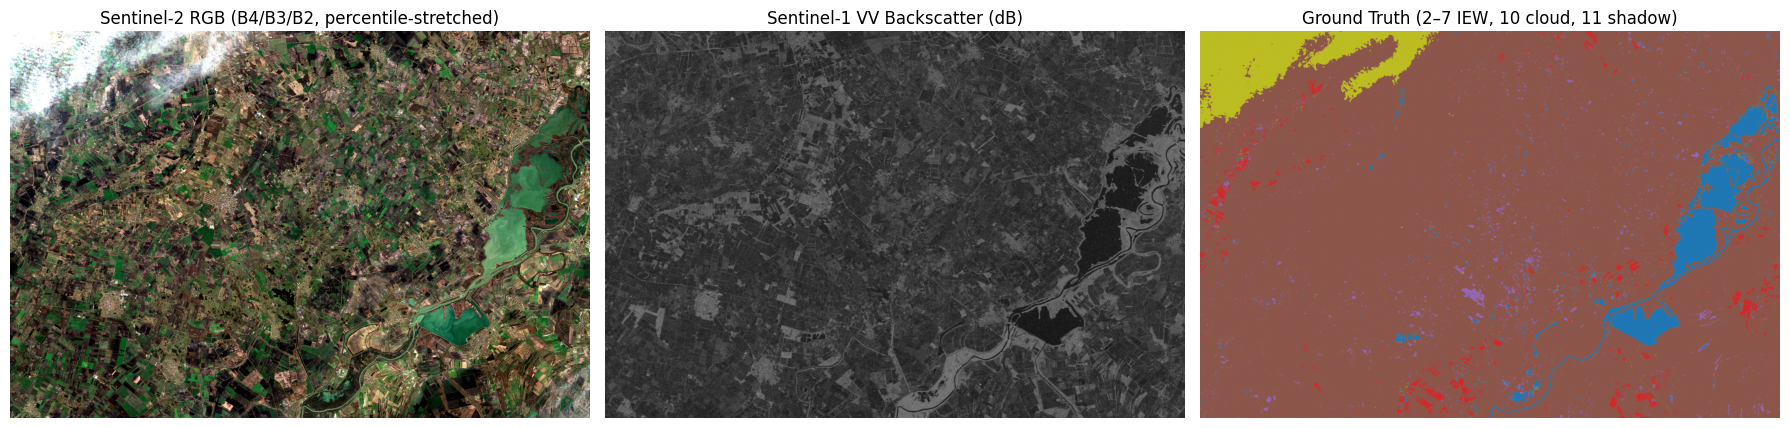


Class pixel counts:
  class 2: 812,770 px (4.18%)
  class 3: 43,644 px (0.22%)
  class 4: 47,309 px (0.24%)
  class 5: 344,799 px (1.77%)
  class 6: 289,506 px (1.49%)
  class 7: 17,027,676 px (87.59%)
  class 10: 874,296 px (4.50%)


In [49]:
# Load config; fall back to local merged dataset if the config path doesn't exist.
with open("configs/data.yaml", "r") as f:
    config = yaml.safe_load(f)

dataset_root = config["dataset_root"]
LOCAL_ROOT = Path("C:/E/S5/Deep_Learning/dataset/tifs_FINAL")
if not Path(dataset_root).exists() and LOCAL_ROOT.exists():
    dataset_root = str(LOCAL_ROOT)
    print(f"Config path not found; using local merged dataset: {dataset_root}")
else:
    print(f"Using dataset root from config: {dataset_root}")

train_scenes = get_scene_files(dataset_root, "Train")
sample_scene = train_scenes[1]
print(f"Sample scene: {sample_scene['name']}")

s2_img = read_s2(sample_scene["S2"])
s1_img = read_s1(sample_scene["S1"])
gt_img = read_gt(sample_scene["GT"])

rgb = np.stack([s2_img[3], s2_img[2], s2_img[1]], axis=-1)
rgb = stretch_rgb(rgb)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(rgb)
axes[0].set_title("Sentinel-2 RGB (B4/B3/B2, percentile-stretched)")
axes[0].axis("off")
axes[1].imshow(s1_img[0], cmap="gray")
axes[1].set_title("Sentinel-1 VV Backscatter (dB)")
axes[1].axis("off")
axes[2].imshow(gt_img, cmap="tab10", vmin=2, vmax=11)
axes[2].set_title("Ground Truth (2–7 IEW, 10 cloud, 11 shadow)")
axes[2].axis("off")
plt.tight_layout()
plt.show()

vals, counts = np.unique(gt_img, return_counts=True)
print("\nClass pixel counts:")
for v, c in zip(vals, counts):
    print(f"  class {v}: {c:,} px ({100*c/gt_img.size:.2f}%)")


## 4. Loss Functions

Total loss = **Generalized Dice Loss + Weighted Focal Loss** (paper §3.2). Cloud/shadow pixels (remapped label = 6) are masked out via `ignore_index=6`.

$$GDL = 1 - \frac{2\sum_c w_c \sum_i p_{c,i}g_{c,i}}{\sum_c w_c \sum_i (p_{c,i}+g_{c,i})}, \quad w_c = \frac{1}{(\sum_i g_{c,i})^2}$$

$$WFL = -\alpha_c (1-p_t)^\gamma \log(p_t)$$

In [50]:
class GeneralizedDiceLoss(nn.Module):
    def __init__(self, ignore_index: int = 6, num_classes: int = 6, eps: float = 1e-6):
        super().__init__()
        self.ignore_index = ignore_index
        self.num_classes  = num_classes
        self.eps          = eps

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        probs = F.softmax(logits, dim=1)
        valid_mask = (targets < self.ignore_index).unsqueeze(1)
        probs = probs * valid_mask

        t_clamped = torch.clamp(targets, 0, self.num_classes - 1)
        t_onehot  = F.one_hot(t_clamped, self.num_classes).permute(0, 3, 1, 2).float()
        t_onehot  = t_onehot * valid_mask

        inter  = torch.sum(probs * t_onehot, dim=(0, 2, 3))
        union  = torch.sum(probs + t_onehot, dim=(0, 2, 3))
        cnt    = torch.sum(t_onehot, dim=(0, 2, 3))
        w      = 1.0 / (cnt ** 2 + self.eps)
        w      = w / (w.sum() + self.eps)

        return 1.0 - (2.0 * (w * inter).sum() + self.eps) / ((w * union).sum() + self.eps)


class WeightedFocalLoss(nn.Module):
    def __init__(self, alpha: torch.Tensor = None, gamma: float = 2.0, ignore_index: int = 6):
        super().__init__()
        self.alpha        = alpha
        self.gamma        = gamma
        self.ignore_index = ignore_index

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        C = logits.size(1)
        logits_flat  = logits.permute(0, 2, 3, 1).contiguous().view(-1, C)
        targets_flat = targets.view(-1)

        valid_mask = targets_flat < self.ignore_index
        if not valid_mask.any():
            return torch.tensor(0.0, device=logits.device, requires_grad=True)

        lv = logits_flat[valid_mask]
        tv = targets_flat[valid_mask]

        log_p  = F.log_softmax(lv, dim=1)
        log_pt = log_p[torch.arange(len(tv)), tv]
        pt     = torch.exp(log_pt)
        loss   = -(1.0 - pt) ** self.gamma * log_pt

        if self.alpha is not None:
            loss = loss * self.alpha.to(logits.device)[tv]

        return loss.mean()


print("GeneralizedDiceLoss + WeightedFocalLoss ready")


GeneralizedDiceLoss + WeightedFocalLoss ready


## 5. Model Architecture — SegFormer-B0

SegFormer combines a **hierarchical Mix-Transformer (MiT) encoder** that produces multi-scale features at 1/4, 1/8, 1/16, and 1/32 of the input resolution, with a **lightweight All-MLP decoder** that fuses those features back to 1/4 and predicts per-pixel class logits (upsampled to full resolution in the forward pass).

### Why SegFormer works well for remote sensing

1. **No fixed positional encoding.** The MiT uses 3×3 depthwise convolutions inside its MixFFN as an *implicit* position signal, which means the model is resolution-agnostic at inference — it can accept any input size without bilinear-interpolating a fixed position table (unlike ViT/TransUNet).

2. **Efficient Self-Attention with sequence reduction ratio (SR).** In stage 1 (32×32 spatial with 128×128 input), computing full attention over 1024 tokens would be expensive. Instead the key and value sequences are first spatially reduced to (32/SR)² tokens via a stride-SR convolution, so attention complexity drops from O(N²) to O(N·N/SR²). SR ratios for B0: [8, 4, 2, 1].

3. **All-MLP decoder.** Each stage's feature map is projected to a common 256-dim space, upsampled to the coarsest (H/4) resolution, concatenated, and passed through a single fused 1×1 conv to predict logits — no dilated convolutions, no FPN, no complex multi-scale pyramid. This simplicity is the key insight of SegFormer.

### Tensor shapes through the encoder (128×128 input)

| Stage | Downsample | Spatial | Embed dim | Tokens | SR tokens (K/V) |
|-------|-----------|---------|-----------|--------|-----------------|
| 1 | ÷4 | 32×32 | 32 | 1024 | 4×4 = 16 |
| 2 | ÷8 | 16×16 | 64 | 256 | 4×4 = 16 |
| 3 | ÷16 | 8×8 | 160 | 64 | 4×4 = 16 |
| 4 | ÷32 | 4×4 | 256 | 16 | 4×4 = 16 (no reduction) |

### All-MLP Decoder

Each of the 4 feature maps is: `Linear(embed_dim → 256)` → upsample to 32×32 → `cat` → `Conv1×1(1024 → 256)` → `Conv1×1(256 → 6)` → upsample to 128×128.

In [51]:
# ─── Stochastic Depth (Drop Path) ─────────────────────────────────────────────
def drop_path_fn(x: torch.Tensor, drop_prob: float = 0.0, training: bool = False):
    if drop_prob == 0.0 or not training:
        return x
    keep_prob = 1 - drop_prob
    shape = (x.shape[0],) + (1,) * (x.ndim - 1)
    rt = torch.rand(shape, dtype=x.dtype, device=x.device).floor_()
    rt.add_(keep_prob)
    return x.div(keep_prob) * rt

class DropPath(nn.Module):
    def __init__(self, drop_prob=0.0):
        super().__init__()
        self.drop_prob = drop_prob
    def forward(self, x):
        return drop_path_fn(x, self.drop_prob, self.training)


# ─── Overlapping Patch Embedding ──────────────────────────────────────────────
class OverlapPatchEmbed(nn.Module):
    """Overlapping patch embedding via stride-s convolution with kernel > stride.

    MiT stage 1: patch_size=7, stride=4 (coarse; captures broad spatial structure).
    Stages 2–4: patch_size=3, stride=2 (fine; preserves local boundary detail).
    Overlap (kernel > stride) is what makes these embeddings context-aware,
    unlike ViT's non-overlapping 16×16 patches.
    """
    def __init__(self, in_ch: int, embed_dim: int, patch_size: int, stride: int):
        super().__init__()
        self.proj = nn.Conv2d(
            in_ch, embed_dim,
            kernel_size=patch_size, stride=stride,
            padding=patch_size // 2, bias=False
        )
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x: torch.Tensor):
        x = self.proj(x)                          # (B, C, H', W')
        B, C, H, W = x.shape
        x = x.flatten(2).transpose(1, 2)          # (B, H'*W', C)
        x = self.norm(x)
        return x, H, W


# ─── Efficient Self-Attention ─────────────────────────────────────────────────
class EfficientSelfAttention(nn.Module):
    """Multi-head self-attention with sequence reduction ratio sr_ratio.

    Q attends over all N tokens; K and V are computed from a spatially-pooled
    sequence of N/sr² tokens, reducing attention complexity from O(N²) to
    O(N · N/sr²). With sr=8 and N=1024, K/V have only 16 tokens.
    """
    def __init__(self, dim: int, num_heads: int, sr_ratio: int = 1):
        super().__init__()
        assert dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim  = dim // num_heads
        self.scale     = self.head_dim ** -0.5

        self.q    = nn.Linear(dim, dim, bias=True)
        self.kv   = nn.Linear(dim, dim * 2, bias=True)
        self.proj = nn.Linear(dim, dim)

        self.sr_ratio = sr_ratio
        if sr_ratio > 1:
            self.sr   = nn.Conv2d(dim, dim, kernel_size=sr_ratio, stride=sr_ratio)
            self.norm = nn.LayerNorm(dim)

    def forward(self, x: torch.Tensor, H: int, W: int) -> torch.Tensor:
        B, N, C = x.shape
        q = (self.q(x)
             .reshape(B, N, self.num_heads, self.head_dim)
             .permute(0, 2, 1, 3))  # (B, heads, N, head_dim)

        if self.sr_ratio > 1:
            x_ = x.transpose(1, 2).reshape(B, C, H, W)   # spatial form
            x_ = self.sr(x_).reshape(B, C, -1).transpose(1, 2)  # (B, N', C)
            x_ = self.norm(x_)
        else:
            x_ = x

        kv = (self.kv(x_)
              .reshape(B, -1, 2, self.num_heads, self.head_dim)
              .permute(2, 0, 3, 1, 4))  # (2, B, heads, N', head_dim)
        k, v = kv[0], kv[1]

        attn = (q @ k.transpose(-2, -1)) * self.scale     # (B, heads, N, N')
        attn = attn.softmax(dim=-1)

        x = (attn @ v).transpose(1, 2).reshape(B, N, C)  # (B, N, C)
        return self.proj(x)


# ─── Mix-FFN ──────────────────────────────────────────────────────────────────
class MixFFN(nn.Module):
    """Mix-FFN: FC → DW-Conv3×3 → GELU → FC.

    The 3×3 depthwise conv encodes local positional information implicitly.
    This is why SegFormer doesn't need explicit positional encodings — the
    convolution's receptive field acts as a local position signal.
    """
    def __init__(self, dim: int, mlp_ratio: int = 4):
        super().__init__()
        hidden = int(dim * mlp_ratio)
        self.fc1     = nn.Linear(dim, hidden)
        self.dw_conv = nn.Conv2d(hidden, hidden, kernel_size=3, padding=1, groups=hidden)
        self.act     = nn.GELU()
        self.fc2     = nn.Linear(hidden, dim)

    def forward(self, x: torch.Tensor, H: int, W: int) -> torch.Tensor:
        x = self.fc1(x)                                    # (B, N, hidden)
        B, N, hidden = x.shape
        x = x.transpose(1, 2).reshape(B, hidden, H, W)    # → spatial
        x = self.dw_conv(x)
        x = x.flatten(2).transpose(1, 2)                  # → sequence
        x = self.act(x)
        x = self.fc2(x)
        return x


# ─── Transformer Block ────────────────────────────────────────────────────────
class TransformerBlock(nn.Module):
    def __init__(self, dim: int, num_heads: int, mlp_ratio: int = 4,
                 sr_ratio: int = 1, drop_path: float = 0.0):
        super().__init__()
        self.norm1     = nn.LayerNorm(dim)
        self.attn      = EfficientSelfAttention(dim, num_heads, sr_ratio)
        self.norm2     = nn.LayerNorm(dim)
        self.ffn       = MixFFN(dim, mlp_ratio)
        self.drop_path = DropPath(drop_path) if drop_path > 0.0 else nn.Identity()

    def forward(self, x: torch.Tensor, H: int, W: int) -> torch.Tensor:
        x = x + self.drop_path(self.attn(self.norm1(x), H, W))
        x = x + self.drop_path(self.ffn(self.norm2(x), H, W))
        return x


# ─── MiT-B0 Encoder ───────────────────────────────────────────────────────────
class MixTransformerEncoder(nn.Module):
    """Mix-Transformer encoder, B0 variant.

    embed_dims = [32, 64, 160, 256]
    depths     = [2, 2, 2, 2]
    num_heads  = [1, 2, 5, 8]
    sr_ratios  = [8, 4, 2, 1]

    Returns a list of 4 feature maps (B, C_i, H/s_i, W/s_i) for
    s = [4, 8, 16, 32] — matching the decoder's upsampling targets.
    """

    def __init__(self, in_ch: int = 11):
        super().__init__()
        embed_dims = [32, 64, 160, 256]
        num_heads  = [1, 2, 5, 8]
        depths     = [2, 2, 2, 2]
        sr_ratios  = [8, 4, 2, 1]
        mlp_ratio  = 4
        dpr = [x.item() for x in torch.linspace(0, 0.1, sum(depths))]
        cur = 0

        # Stage 1: 7×7 overlap embed, stride 4
        self.patch_embed1 = OverlapPatchEmbed(in_ch, embed_dims[0], patch_size=7, stride=4)
        self.block1 = nn.ModuleList([
            TransformerBlock(embed_dims[0], num_heads[0], mlp_ratio, sr_ratios[0], dpr[cur+i])
            for i in range(depths[0])
        ])
        self.norm1 = nn.LayerNorm(embed_dims[0])
        cur += depths[0]

        # Stage 2: 3×3 overlap embed, stride 2
        self.patch_embed2 = OverlapPatchEmbed(embed_dims[0], embed_dims[1], patch_size=3, stride=2)
        self.block2 = nn.ModuleList([
            TransformerBlock(embed_dims[1], num_heads[1], mlp_ratio, sr_ratios[1], dpr[cur+i])
            for i in range(depths[1])
        ])
        self.norm2 = nn.LayerNorm(embed_dims[1])
        cur += depths[1]

        # Stage 3
        self.patch_embed3 = OverlapPatchEmbed(embed_dims[1], embed_dims[2], patch_size=3, stride=2)
        self.block3 = nn.ModuleList([
            TransformerBlock(embed_dims[2], num_heads[2], mlp_ratio, sr_ratios[2], dpr[cur+i])
            for i in range(depths[2])
        ])
        self.norm3 = nn.LayerNorm(embed_dims[2])
        cur += depths[2]

        # Stage 4
        self.patch_embed4 = OverlapPatchEmbed(embed_dims[2], embed_dims[3], patch_size=3, stride=2)
        self.block4 = nn.ModuleList([
            TransformerBlock(embed_dims[3], num_heads[3], mlp_ratio, sr_ratios[3], dpr[cur+i])
            for i in range(depths[3])
        ])
        self.norm4 = nn.LayerNorm(embed_dims[3])

    def forward(self, x: torch.Tensor):
        B = x.shape[0]
        outs = []

        # Stage 1
        x, H, W = self.patch_embed1(x)
        for blk in self.block1:
            x = blk(x, H, W)
        x = self.norm1(x)
        outs.append(x.reshape(B, H, W, -1).permute(0, 3, 1, 2))  # (B, 32, H/4, W/4)

        # Stage 2
        x, H, W = self.patch_embed2(outs[-1])
        for blk in self.block2:
            x = blk(x, H, W)
        x = self.norm2(x)
        outs.append(x.reshape(B, H, W, -1).permute(0, 3, 1, 2))  # (B, 64, H/8, W/8)

        # Stage 3
        x, H, W = self.patch_embed3(outs[-1])
        for blk in self.block3:
            x = blk(x, H, W)
        x = self.norm3(x)
        outs.append(x.reshape(B, H, W, -1).permute(0, 3, 1, 2))  # (B, 160, H/16, W/16)

        # Stage 4
        x, H, W = self.patch_embed4(outs[-1])
        for blk in self.block4:
            x = blk(x, H, W)
        x = self.norm4(x)
        outs.append(x.reshape(B, H, W, -1).permute(0, 3, 1, 2))  # (B, 256, H/32, W/32)

        return outs  # [c1@H/4, c2@H/8, c3@H/16, c4@H/32]


# ─── All-MLP Decoder ──────────────────────────────────────────────────────────
class SegFormerHead(nn.Module):
    """All-MLP decoder from SegFormer (no dilated convolutions or FPN).

    Each of the 4 encoder feature maps is:
    1. Projected with a Linear to decoder_dim (256).
    2. Upsampled to c1's resolution (H/4, W/4) via bilinear interpolation.
    3. Concatenated along the channel axis → 4×decoder_dim channels.
    4. Fused via Conv1×1(4D → D) + BN + ReLU + Dropout.
    5. Classified via Conv1×1(D → num_classes).
    The forward in SegFormer then upsamples the logits to input resolution.
    """

    def __init__(self, embed_dims=(32, 64, 160, 256),
                 decoder_dim: int = 256, num_classes: int = 6):
        super().__init__()
        self.proj = nn.ModuleList([
            nn.Linear(d, decoder_dim) for d in embed_dims
        ])
        self.fuse = nn.Sequential(
            nn.Conv2d(decoder_dim * len(embed_dims), decoder_dim, kernel_size=1, bias=False),
            nn.BatchNorm2d(decoder_dim),
            nn.ReLU(inplace=True),
            nn.Dropout2d(0.1),
        )
        self.classifier = nn.Conv2d(decoder_dim, num_classes, kernel_size=1)

    def forward(self, features):
        H0, W0 = features[0].shape[2], features[0].shape[3]  # H/4, W/4
        projected = []
        for feat, proj in zip(features, self.proj):
            B, C, Hf, Wf = feat.shape
            f = feat.flatten(2).transpose(1, 2)       # (B, Hf*Wf, C)
            f = proj(f)                                # (B, Hf*Wf, decoder_dim)
            f = f.transpose(1, 2).reshape(B, -1, Hf, Wf)  # (B, decoder_dim, Hf, Wf)
            if (Hf, Wf) != (H0, W0):
                f = F.interpolate(f, size=(H0, W0), mode="bilinear", align_corners=False)
            projected.append(f)

        x = self.fuse(torch.cat(projected, dim=1))  # (B, decoder_dim, H/4, W/4)
        return self.classifier(x)                   # (B, num_classes, H/4, W/4)


# ─── Full SegFormer ───────────────────────────────────────────────────────────
class SegFormer(nn.Module):
    """SegFormer-B0: MiT-B0 encoder + All-MLP decoder.
    ~3.7M parameters. Input: (B, 11, H, W). Output: (B, 6, H, W).
    """

    def __init__(self, in_ch: int = 11, num_classes: int = 6):
        super().__init__()
        self.encoder = MixTransformerEncoder(in_ch)
        self.decoder = SegFormerHead(
            embed_dims=(32, 64, 160, 256),
            decoder_dim=256,
            num_classes=num_classes
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        H, W  = x.shape[2], x.shape[3]
        feats = self.encoder(x)               # [H/4, H/8, H/16, H/32] features
        logits = self.decoder(feats)          # (B, num_classes, H/4, W/4)
        return F.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)


# --- Sanity check ------------------------------------------------------------
_m = SegFormer(in_ch=11, num_classes=6)
total_params = sum(p.numel() for p in _m.parameters())
trainable    = sum(p.numel() for p in _m.parameters() if p.requires_grad)
print(f"SegFormer-B0: {total_params/1e6:.2f}M params ({trainable/1e6:.2f}M trainable)")

_x = torch.randn(2, 11, 128, 128)
_y = _m(_x)
print(f"Forward pass: input {tuple(_x.shape)} → output {tuple(_y.shape)}  ✓")
del _m, _x, _y


SegFormer-B0: 3.73M params (3.73M trainable)
Forward pass: input (2, 11, 128, 128) → output (2, 6, 128, 128)  ✓


## 6. Dataset & Dataloader Setup

Full non-overlapping 128×128 patch grid (~13k patches across 14 training scenes). Each epoch trains on a fresh random subset of 4,000 patches — ~31% of the grid — so there is no permanent spatial blind spot across epochs, and per-epoch wall-clock time stays manageable on CPU.

The validation loader uses a sparser stride=512 during training for fast feedback; the full non-overlapping grid is used at final evaluation.

In [52]:
# Class weights: inverse-frequency over training set, mean-normalized.
# (Same pixel counts as the other backbone notebooks — the training split is identical.)
TRAIN_PIXEL_COUNTS = [7674525, 651441, 900550, 4493763, 3450129, 195012790]
counts       = np.array(TRAIN_PIXEL_COUNTS, dtype=np.float32)
weights      = counts.sum() / (len(counts) * counts)
weights      = weights / weights.mean()
class_weights = torch.from_numpy(weights).float()
print(f"Class weights: {[f'{w:.3f}' for w in class_weights.tolist()]}")

BATCH_SIZE    = 32   # paper §4.1
PATCH_SIZE    = 128  # SegFormer requires ≥128 (see §0 deviations)

train_dataset = FloodPatchDataset(
    dataset_root=dataset_root,
    split="Train",
    patch_size=PATCH_SIZE,
    stride=PATCH_SIZE,   # non-overlapping full grid
    augment=True,
    load_s1=False,       # S2-only backbone (same as 01–03)
)

val_dataset = FloodPatchDataset(
    dataset_root=dataset_root,
    split="Test",
    patch_size=PATCH_SIZE,
    stride=512,          # sparse val grid during training for speed
    augment=False,
    load_s1=False,
)

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Train patches: {len(train_dataset):,} | Val patches (sparse): {len(val_dataset):,}")


Class weights: ['0.237', '2.797', '2.023', '0.405', '0.528', '0.009']
Building Train patch index (patch=128, stride=128)...
  14 scenes → 12,894 patches
Building Test patch index (patch=128, stride=512)...
  9 scenes → 558 patches
Train patches: 12,894 | Val patches (sparse): 558


## 7. Model, Loss, and Optimizer Setup

Matches §4.1 verbatim: Adam, lr=1e-4, 100 epochs, batch=32. No scheduler, no weight decay (paper does not state either).

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = SegFormer(in_ch=11, num_classes=6).to(device)

EPOCHS        = 100
LEARNING_RATE = 1e-4

criterion_gdl = GeneralizedDiceLoss(ignore_index=6, num_classes=6)
criterion_wfl = WeightedFocalLoss(alpha=class_weights, gamma=2.0, ignore_index=6)
optimizer     = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

print(f"Model: SegFormer-B0 ({sum(p.numel() for p in model.parameters())/1e6:.2f}M params)")
print(f"Optimizer: Adam(lr={LEARNING_RATE}) | Epochs: {EPOCHS} | Batch: {BATCH_SIZE}")

## 8. Training Loop

100 epochs, constant LR, fresh random subset of 4,000 patches per epoch. Saves best checkpoint by val loss to `outputs/checkpoints/segformer_b0_best.pt`.

In [ ]:
SAMPLES_PER_EPOCH = 4000   # ~31% of the full 128x128 grid per epoch
CKPT_PATH         = Path("outputs/checkpoints/segformer_b0_best.pt")
CKPT_PATH.parent.mkdir(parents=True, exist_ok=True)

epoch_rng  = np.random.default_rng(0)
history    = {"train_loss": [], "val_loss": [], "train_gdl": [], "train_wfl": []}
best_val   = float("inf")

print(f"Training SegFormer-B0 for {EPOCHS} epochs...")
print(f"  Samples/epoch: {SAMPLES_PER_EPOCH} | Val loader: {len(val_loader)} batches")
print(f"  Checkpoint: {CKPT_PATH}")
print()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    e_loss = e_gdl = e_wfl = 0.0

    idx = epoch_rng.choice(
        len(train_dataset),
        size=min(SAMPLES_PER_EPOCH, len(train_dataset)),
        replace=False
    )
    train_loader = DataLoader(
        Subset(train_dataset, idx),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=0
    )

    for s2, _, gt in train_loader:
        s2, gt = s2.to(device), gt.to(device)
        optimizer.zero_grad()
        logits   = model(s2)
        loss_gdl = criterion_gdl(logits, gt)
        loss_wfl = criterion_wfl(logits, gt)
        loss     = loss_gdl + loss_wfl
        loss.backward()
        optimizer.step()
        e_loss += loss.item()
        e_gdl  += loss_gdl.item()
        e_wfl  += loss_wfl.item()

    n = len(train_loader)
    avg_train = e_loss / n
    avg_gdl   = e_gdl  / n
    avg_wfl   = e_wfl  / n

    model.eval()
    v_loss = 0.0
    with torch.no_grad():
        for s2, _, gt in val_loader:
            s2, gt = s2.to(device), gt.to(device)
            logits = model(s2)
            v_loss += (criterion_gdl(logits, gt) + criterion_wfl(logits, gt)).item()
    avg_val = v_loss / len(val_loader)

    history["train_loss"].append(avg_train)
    history["train_gdl"].append(avg_gdl)
    history["train_wfl"].append(avg_wfl)
    history["val_loss"].append(avg_val)

    elapsed = time.time() - t0
    star    = " *" if avg_val < best_val else ""
    print(f"Epoch {epoch:3d}/{EPOCHS} | "
          f"train={avg_train:.4f} (GDL={avg_gdl:.4f} WFL={avg_wfl:.4f}) | "
          f"val={avg_val:.4f} | {elapsed:.0f}s{star}")

    if avg_val < best_val:
        best_val = avg_val
        torch.save({"epoch": epoch, "model_state": model.state_dict(),
                    "val_loss": best_val}, CKPT_PATH)

print(f"\nTraining complete. Best val loss: {best_val:.4f} → {CKPT_PATH}")


## 9. Loss Curves

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(history["train_loss"], label="Train Total")
plt.plot(history["train_gdl"],  label="Train GDL")
plt.plot(history["train_wfl"],  label="Train WFL")
plt.plot(history["val_loss"],   label="Val Total", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("SegFormer-B0 Loss Curves (GDL + WFL)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## 10. Load Best Checkpoint

Reload the best val-loss checkpoint before running full evaluation.

In [ ]:
ckpt = torch.load(CKPT_PATH, map_location=device)
model.load_state_dict(ckpt["model_state"])
print(f"Loaded checkpoint from epoch {ckpt['epoch']} (val_loss={ckpt['val_loss']:.4f})")


## 11. Evaluation on Full Test Set

Non-overlapping 128×128 patches. Per-class pixel-level Precision/Recall/F1 (cloud/shadow pixels excluded).

Two overall rows are reported:
- **ALL (classes 0–5):** includes the dominant "not affected" class — inflated, not comparable to paper.
- **Water-related only (classes 0–4, i.e. raw 2–6):** excludes class 7 (not affected) — directly comparable to paper Table 1.

In [ ]:
eval_dataset = FloodPatchDataset(
    dataset_root=dataset_root,
    split="Test",
    patch_size=PATCH_SIZE,
    stride=PATCH_SIZE,  # non-overlapping for evaluation
    augment=False,
    load_s1=False,
)
eval_loader = DataLoader(eval_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

model.eval()
tp  = np.zeros(6, dtype=np.int64)
fp  = np.zeros(6, dtype=np.int64)
fn  = np.zeros(6, dtype=np.int64)
cnt = np.zeros(6, dtype=np.int64)

with torch.no_grad():
    for s2, _, gt in eval_loader:
        preds = torch.argmax(model(s2.to(device)), dim=1).cpu().numpy()
        gt_np = gt.numpy()
        for b in range(preds.shape[0]):
            p, g = preds[b], gt_np[b]
            valid = g < 6
            for c in range(6):
                pc = (p == c) & valid
                gc = (g == c) & valid
                tp[c]  += (pc &  gc).sum()
                fp[c]  += (pc & ~gc).sum()
                fn[c]  += (~pc & gc).sum()
                cnt[c] += gc.sum()

CLASS_NAMES = [
    "Open surface water     (raw 2)",
    "Soil seriously affected(raw 3)",
    "Soil moderately affected(raw 4)",
    "Soil slightly affected (raw 5)",
    "Vegetation affected    (raw 6)",
    "Not affected areas     (raw 7)",
]

pr_list, rc_list, f1_list = [], [], []
for c in range(6):
    pr = tp[c] / (tp[c] + fp[c] + 1e-10)
    rc = tp[c] / (tp[c] + fn[c] + 1e-10)
    f1 = 2 * pr * rc / (pr + rc + 1e-10)
    pr_list.append(pr); rc_list.append(rc); f1_list.append(f1)

print("\n" + "=" * 75)
print(f"{'Cls':<5}{'Name':<35}{'Pr (%)':>8}{'Rc (%)':>8}{'F1 (%)':>8}  {'Pixels':>10}")
print("=" * 75)
for c in range(6):
    print(f"{c:<5}{CLASS_NAMES[c]:<35}{pr_list[c]*100:>8.2f}{rc_list[c]*100:>8.2f}"
          f"{f1_list[c]*100:>8.2f}  {cnt[c]:>10,}")
print("=" * 75)

# ALL (classes 0–5) — pixel-weighted
total = cnt.sum()
all_pr = sum(pr_list[c] * cnt[c] for c in range(6)) / (total + 1e-10)
all_rc = sum(rc_list[c] * cnt[c] for c in range(6)) / (total + 1e-10)
all_f1 = sum(f1_list[c] * cnt[c] for c in range(6)) / (total + 1e-10)
print(f"{'':5}{'ALL (classes 0–5, with not-affected)':<35}"
      f"{all_pr*100:>8.2f}{all_rc*100:>8.2f}{all_f1*100:>8.2f}  {total:>10,}")

# Water-related only (classes 0–4, raw 2–6) — comparable to paper Table 1
cnt5   = cnt[:5].sum()
w_pr   = sum(pr_list[c] * cnt[c] for c in range(5)) / (cnt5 + 1e-10)
w_rc   = sum(rc_list[c] * cnt[c] for c in range(5)) / (cnt5 + 1e-10)
w_f1   = sum(f1_list[c] * cnt[c] for c in range(5)) / (cnt5 + 1e-10)
print(f"{'':5}{'WATER-RELATED ONLY (raw 2–6, Table 1)':<35}"
      f"{w_pr*100:>8.2f}{w_rc*100:>8.2f}{w_f1*100:>8.2f}  {cnt5:>10,}")
print("=" * 75)
print(f"\nPaper Table 1 reference (best backbone — RUPNet): Pr=76.35  Rc=86.70  F1=81.19")


## 12. Visualizing Predictions

In [ ]:
def patch_class_diversity(idx):
    _, _, gt = eval_dataset[idx]
    valid = gt.numpy()
    valid = valid[valid < 6]
    return len(np.unique(valid)) if valid.size else 0

# Scan every 37th patch (avoids aliasing with the patch grid) for class diversity
scores  = [(i, patch_class_diversity(i)) for i in range(0, len(eval_dataset), 37)]
scores.sort(key=lambda t: t[1], reverse=True)
chosen  = [i for i, _ in scores[:3]]
print(f"Chosen patch indices (class diversity): {[(i, s) for i, s in scores[:3]]}")

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for row, patch_idx in enumerate(chosen):
    s2, _, gt = eval_dataset[patch_idx]
    with torch.no_grad():
        pred = torch.argmax(model(s2.unsqueeze(0).to(device)), dim=1).squeeze(0).cpu().numpy()

    # Undo S2 standardization → reflectance for display
    s2_np = s2.numpy()
    rgb   = np.stack([s2_np[3], s2_np[2], s2_np[1]], axis=-1)
    rgb   = rgb * S2_STD[[3, 2, 1]] + S2_MEAN[[3, 2, 1]]
    rgb   = stretch_rgb(rgb)

    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title("Input S2 RGB")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(gt.numpy(), cmap="tab10", vmin=0, vmax=5)
    axes[row, 1].set_title("GT Mask")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(pred, cmap="tab10", vmin=0, vmax=5)
    axes[row, 2].set_title("SegFormer-B0 Prediction")
    axes[row, 2].axis("off")

plt.suptitle("SegFormer-B0 — Most Class-Diverse Test Patches", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()
